# Experiment: Euclidean Distance Calculation and k-NN Classification
**Topic:** Distance Metrics & Non-Parametric Neighborhood Classification  
**Algorithm:** Euclidean ($L_2$) Metric & $k$-Nearest Neighbors Majority Voting  
**Objective:** Calculate pairwise geometric distances between an unlabelled query point and existing data points, rank nearest neighbors, and determine class membership via majority voting.

---

## 1. Mathematical Principles of Metric Distances

A distance function $d: X \times X \to \mathbb{R}$ is a valid mathematical metric if it satisfies four foundational axioms for all $\mathbf{x}, \mathbf{y}, \mathbf{z} \in X$:
1. **Non-negativity:** $d(\mathbf{x}, \mathbf{y}) \ge 0$
2. **Identity of indiscernibles:** $d(\mathbf{x}, \mathbf{y}) = 0 \iff \mathbf{x} = \mathbf{y}$
3. **Symmetry:** $d(\mathbf{x}, \mathbf{y}) = d(\mathbf{y}, \mathbf{x})$
4. **Triangle inequality:** $d(\mathbf{x}, \mathbf{z}) \le d(\mathbf{x}, \mathbf{y}) + d(\mathbf{y}, \mathbf{z})$

### Common Metric Formulations in $\mathbb{R}^2$

#### 1. Euclidean Distance ($L_2$ Norm):
$$d_{\text{Euclidean}}(\mathbf{x}, \mathbf{y}) = \sqrt{(x_1 - y_1)^2 + (x_2 - y_2)^2}$$

#### 2. Manhattan Distance ($L_1$ Norm):
$$d_{\text{Manhattan}}(\mathbf{x}, \mathbf{y}) = |x_1 - y_1| + |x_2 - y_2|$$

#### 3. Chebyshev Distance ($L_\infty$ Norm):
$$d_{\text{Chebyshev}}(\mathbf{x}, \mathbf{y}) = \max\big(|x_1 - y_1|, |x_2 - y_2|\big)$$


In [1]:
# Import dependencies
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.neighbors import KNeighborsClassifier

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 120


## 2. Experimental Dataset

We analyze an optical color calibration dataset defined by two perceptual features:
- **Brightness**: Intensity scale ($0$ to $100$).
- **Saturation**: Color purity scale ($0$ to $100$).
- **Class**: Binary chromatic label (`Red` vs. `Blue`).


In [2]:
# Define known reference observations
data = pd.DataFrame({
    'Brightness': [40, 50, 60, 10, 70, 60, 25],
    'Saturation': [20, 50, 90, 25, 70, 10, 80],
    'Class': ['Red', 'Blue', 'Blue', 'Red', 'Blue', 'Red', 'Blue']
})

print("Known Reference Points:")
display(data)

# Query instance
query_point = {'Brightness': 45, 'Saturation': 40}
print(f"\nUnlabelled Query Point: ({query_point['Brightness']}, {query_point['Saturation']})")


Known Reference Points:


,Brightness,Saturation,Class
0,40,20,Red
1,50,50,Blue
2,60,90,Blue
3,10,25,Red
4,70,70,Blue
5,60,10,Red
6,25,80,Blue



Unlabelled Query Point: (45, 40)


## 3. Step-by-Step Distance Computation

For each known observation $(B_i, S_i)$, the Euclidean distance to query point $(B_q, S_q) = (45, 40)$ is:
$$d_i = \sqrt{(45 - B_i)^2 + (40 - S_i)^2}$$

We compute Euclidean, Manhattan, and Chebyshev metrics for comparative analysis.


In [3]:
# Vectorized metric computations
qb, qs = query_point['Brightness'], query_point['Saturation']

data['Delta_Brightness'] = data['Brightness'] - qb
data['Delta_Saturation'] = data['Saturation'] - qs

# Distance formulas
data['Euclidean_Dist'] = np.sqrt(data['Delta_Brightness']**2 + data['Delta_Saturation']**2)
data['Manhattan_Dist'] = np.abs(data['Delta_Brightness']) + np.abs(data['Delta_Saturation'])
data['Chebyshev_Dist'] = np.maximum(np.abs(data['Delta_Brightness']), np.abs(data['Delta_Saturation']))

# Display detailed breakdown
print("Distance Calculation Breakdown:")
display_cols = ['Brightness', 'Saturation', 'Class', 'Delta_Brightness', 'Delta_Saturation',
                'Euclidean_Dist', 'Manhattan_Dist', 'Chebyshev_Dist']
display(data[display_cols].round(3))


Distance Calculation Breakdown:


,Brightness,Saturation,Class,Delta_Brightness,Delta_Saturation,Euclidean_Dist,Manhattan_Dist,Chebyshev_Dist
0,40,20,Red,-5,-20,20.616,25,20
1,50,50,Blue,5,10,11.180,15,10
2,60,90,Blue,15,50,52.202,65,50
3,10,25,Red,-35,-15,38.079,50,35
4,70,70,Blue,25,30,39.051,55,30
5,60,10,Red,15,-30,33.541,45,30
6,25,80,Blue,-20,40,44.721,60,40


## 4. Nearest Neighbor Ranking & Plurality Voting

We sort observations in ascending order of Euclidean distance to extract the $k=3$ nearest neighbors.


In [4]:
# Sort by Euclidean distance
sorted_neighbors = data.sort_values('Euclidean_Dist').reset_index(drop=True)

k = 3
k_nearest = sorted_neighbors.head(k)

print(f"Top k = {k} Nearest Neighbors:")
display(k_nearest[['Brightness', 'Saturation', 'Class', 'Euclidean_Dist']].round(3))

# Plurality voting
votes = k_nearest['Class'].value_counts()
predicted_class = votes.index[0]

print(f"\nVote Breakdown among k={k} nearest neighbors:")
for cls, count in votes.items():
    print(f"  {cls}: {count} vote(s)")
print(f"\nFinal Predicted Class for Query Point ({qb}, {qs}): {predicted_class}")


Top k = 3 Nearest Neighbors:


,Brightness,Saturation,Class,Euclidean_Dist
0,50,50,Blue,11.180
1,40,20,Red,20.616
2,60,10,Red,33.541



Vote Breakdown among k=3 nearest neighbors:
  Red: 2 vote(s)
  Blue: 1 vote(s)

Final Predicted Class for Query Point (45, 40): Red


## 5. Geometric Feature Space Visualization

We illustrate the 2D feature plane, depicting:
- Reference points color-coded by class.
- The unlabelled query point.
- Distance vectors connecting the query point to its $k=3$ nearest neighbors.
- The boundary circle representing the neighborhood radius $r = d_{(k)}$.


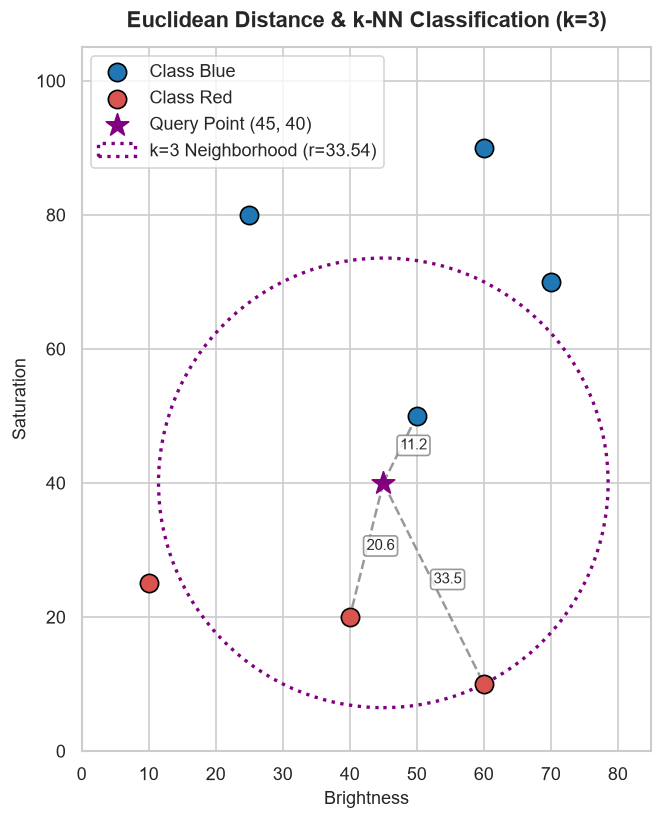

In [5]:
plt.figure(figsize=(9, 7))

# Scatter plot of reference points
for cls, group in data.groupby('Class'):
    color = '#d9534f' if cls == 'Red' else '#1f77b4'
    plt.scatter(group['Brightness'], group['Saturation'], label=f"Class {cls}",
                color=color, s=120, edgecolor='black', zorder=3)

# Query point
plt.scatter(qb, qs, color='purple', s=200, marker='*', label="Query Point (45, 40)", zorder=4)

# Draw vectors to k-nearest neighbors
radius = k_nearest.iloc[-1]['Euclidean_Dist']
for _, row in k_nearest.iterrows():
    plt.plot([qb, row['Brightness']], [qs, row['Saturation']],
             color='gray', linestyle='--', linewidth=1.5, alpha=0.8)
    mid_x = (qb + row['Brightness']) / 2
    mid_y = (qs + row['Saturation']) / 2
    plt.text(mid_x, mid_y, f"{row['Euclidean_Dist']:.1f}", fontsize=9,
             bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="gray", alpha=0.8))

# Neighborhood radius circle
circle = plt.Circle((qb, qs), radius, color='purple', fill=False,
                    linestyle=':', linewidth=2, label=f'k={k} Neighborhood (r={radius:.2f})')
plt.gca().add_patch(circle)

plt.title(f"Euclidean Distance & k-NN Classification (k={k})", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Brightness", fontsize=11)
plt.ylabel("Saturation", fontsize=11)
plt.xlim(0, 85)
plt.ylim(0, 105)
plt.gca().set_aspect('equal', adjustable='box')
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


## 6. Formal Verification with Scikit-Learn

We verify that our manual implementation strictly matches `sklearn.neighbors.KNeighborsClassifier`.


In [6]:
X_train = data[['Brightness', 'Saturation']].values
y_train = data['Class'].values

knn = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
knn.fit(X_train, y_train)

sklearn_pred = knn.predict([[qb, qs]])[0]
distances, indices = knn.kneighbors([[qb, qs]])

print(f"Scikit-Learn Predicted Class: {sklearn_pred}")
print(f"Scikit-Learn Neighbor Distances: {distances[0].round(3)}")
print(f"Matches Manual Prediction: {sklearn_pred == predicted_class}")


Scikit-Learn Predicted Class: Red
Scikit-Learn Neighbor Distances: [11.18  20.616 33.541]
Matches Manual Prediction: True


## 7. Observations & Conclusion

1. **Distance Ranking:** The closest observation to $(45, 40)$ is $(50, 50)$ with $d \approx 11.18$ (Blue), followed by $(40, 20)$ with $d \approx 20.62$ (Red) and $(60, 10)$ with $d \approx 33.54$ (Red).
2. **Majority Vote Decision:** Among the $k=3$ nearest neighbors, Red holds 2 votes while Blue holds 1 vote. Consequently, the query instance is classified as **Red**.
3. **Scale Invariance Consideration:** In this dataset, both Brightness and Saturation span similar numerical domains ($[0, 100]$). If one feature had a vastly wider scale (e.g., $10^4$), it would artificially dominate Euclidean distance calculations without standardization.
